# 01 — Analyse des données PEGS

**Objectif du projet** : estimer la magnitude de moment **Mw** d'un grand séisme à partir des
*Prompt Elasto-Gravity Signals* (PEGS), signaux qui voyagent à la vitesse de la lumière et arrivent
**avant** les ondes P.

**Source des données** : dossier `data/` du dépôt PEGSGraph — K. Juhel, C. Hourcade, G. Arias, Q. Bletery,
<https://gitlab.com/kjuhel/pegsgraph> (licence GPL-3.0), article associé : Hourcade, Juhel & Bletery (2025),
*JGR: Machine Learning and Computation*, <https://doi.org/10.1029/2024JH000360>.
Date de consultation : 11/10/2026.

**Contenu** : description, qualité, cible, relations, audit de fuite.
Chaque figure est suivie d'une phrase d'interprétation.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # pour importer src/ depuis notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch

from src import config as C
from src import pegs_io as io

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C.FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)
import warnings
warnings.filterwarnings("ignore", message="All-NaN slice")   # stations jamais actives : bruit médian = NaN (voulu)

## 1. Inventaire des fichiers

Les données sont au format **HDF5** (`.h5`) : un fichier contient plusieurs tableaux nommés (« datasets »).

In [2]:
files = sorted(C.DATA_DIR.rglob("*.h5"))
inventaire = pd.concat([io.describe_h5(p) for p in files], ignore_index=True)
taille = pd.DataFrame({"fichier": [p.name for p in files],
                       "taille (Mo)": [round(p.stat().st_size / 1e6, 1) for p in files]})
taille

,fichier,taille (Mo)
0,01_kernel_PEGS_alaska_complete_grid.h5,50.3
1,03_PEGS_db_alaska_complete_grid_tiny.h5,8.4
2,04_noise_db_alaska_complete_example.h5,94.5
3,PEGS_Z_database_QSSP_AK135_F1_20km.h5,83.6
4,graph_db_alaska_Q4_grid_random_complete_tiny.h5,19.8
5,201801230931A_complete.h5,0.7
6,202007220612A_complete.h5,0.7
7,202010192054A_complete.h5,0.7
8,202107290615A_legacy.h5,0.4


In [3]:
# Détail des tableaux des 4 fichiers principaux
inventaire[inventaire.fichier.isin([C.KERNEL_FILE.name, C.PEGS_DB_FILE.name,
                                    C.NOISE_FILE.name, C.GRAPH_DB_FILE.name])]

,fichier,dataset,forme,type
0,01_kernel_PEGS_alaska_complete_grid.h5,dip,"(15,)",float32
1,01_kernel_PEGS_alaska_complete_grid.h5,kerPEGS,"(15, 273, 512, 1, 6)",float32
2,01_kernel_PEGS_alaska_complete_grid.h5,kertp,"(15, 273)",float32
3,01_kernel_PEGS_alaska_complete_grid.h5,srcdep,"(15,)",float32
4,01_kernel_PEGS_alaska_complete_grid.h5,srclat,"(15,)",float32
5,01_kernel_PEGS_alaska_complete_grid.h5,srclon,"(15,)",float32
6,01_kernel_PEGS_alaska_complete_grid.h5,stacode,"(273,)",|S10
7,01_kernel_PEGS_alaska_complete_grid.h5,stalat,"(273,)",float32
8,01_kernel_PEGS_alaska_complete_grid.h5,stalon,"(273,)",float32
9,01_kernel_PEGS_alaska_complete_grid.h5,strike,"(15,)",float32


**Rôle de chaque fichier** (déduit de leur contenu, vérifié plus bas) :

| Fichier | Contenu | Rôle |
|---|---|---|
| `01_kernel_PEGS_...h5` | Réponse PEGS des 273 stations à 6 sources élémentaires, pour 15 positions de source | « Brique physique » pour **générer** de nouveaux séismes |
| `QSSP/PEGS_Z_database_...F1..F6` | Même chose sur une grille 201×201 de positions (modèle de Terre AK135) | Brique utilisée par les scripts officiels pour calculer les noyaux ci-dessus |
| `03_PEGS_db_..._tiny.h5` | 15 séismes synthétiques **sans bruit** + leurs paramètres (Mw, mécanisme, fonction source) | Exemple de base générée |
| `04_noise_db_..._example.h5` | 24 fenêtres d'1 h de **bruit réel** enregistré aux 273 stations | Rendre les synthétiques réalistes |
| `graph_db_..._tiny.h5` | Les 15 mêmes séismes **avec bruit**, déjà répartis train/valid/test (10/3/2) | Format d'entrée du modèle PEGSGraph |
| `real_time/*.h5` | **4 vrais séismes** d'Alaska enregistrés | Test final sur données réelles |

Le mot *tiny* est important : les bases prêtes à l'emploi ne contiennent que **15 séismes**.

## 2. Où sont les stations et les sources ?

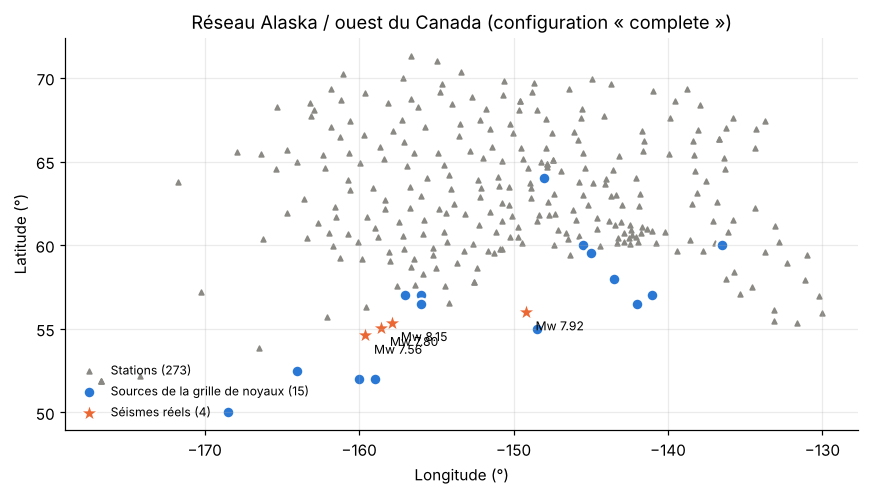

,fichier,date,mw,lat,lon,n_stations,stations_actives_%
0,201801230931A_complete.h5,20180123,7.924992,56.004002,-149.166000,273,87.5
1,202007220612A_complete.h5,20200722,7.803576,55.070999,-158.595993,273,89.4
2,202010192054A_complete.h5,20201019,7.560291,54.602001,-159.626007,273,91.2
3,202107290615A_legacy.h5,20210729,8.145514,55.362999,-157.888000,178,94.9


In [4]:
sta = io.load_stations(C.GRAPH_DB_FILE)
ker = io.load_kernels(C.KERNEL_FILE)
real_files = sorted(C.REAL_DIR.glob("*.h5"))
real = []
for p in real_files:
    d = io.load_graph_split(p, "test")
    real.append({"fichier": p.name, "date": p.name[:8], "mw": float(d["mw"][0]),
                 "lat": float(d["srclat"][0]), "lon": float(d["srclon"][0]),
                 "n_stations": d["data"].shape[1], "stations_actives_%": round(100 * d["flag"].mean(), 1)})
real = pd.DataFrame(real)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(sta.lon, sta.lat, s=10, marker="^", color=C.C_MUTED, label=f"Stations ({len(sta)})")
ax.scatter(ker["srclon"], ker["srclat"], s=60, color=C.C_SIGNAL, edgecolor="white", linewidth=1.5,
           label=f"Sources de la grille de noyaux ({len(ker['srclat'])})")
ax.scatter(real.lon, real.lat, s=150, marker="*", color=C.C_NOISY, edgecolor="white", linewidth=1,
           label=f"Séismes réels ({len(real)})")
for _, r in real.iterrows():
    ax.annotate(f"Mw {r.mw:.2f}", (r.lon, r.lat), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
ax.set_title("Réseau Alaska / ouest du Canada (configuration « complete »)")
ax.legend(loc="lower left", fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_carte_stations.png"); plt.show()
real

**Lecture** : les 273 stations couvrent l'Alaska et l'ouest du Canada ; les sources synthétiques sont placées
sur 15 points le long des zones sismiques, et les 4 séismes réels (Kodiak 2018, Shumagin 2020, Sand Point 2020,
Chignik 2021) sont dans la zone couverte. Pour Chignik 2021, seule la configuration *legacy* (178 stations) est fournie.

## 3. Unités et fréquence d'échantillonnage

On ne suppose rien : on **vérifie**.
- Les signaux sont mis à zéro à partir de l'arrivée de l'onde P (`tp`, en secondes). Si l'échantillonnage est de 1 Hz,
  le dernier échantillon non nul doit être à l'indice ≈ `tp`.
- Les amplitudes : les PEGS attendus font au plus quelques nm/s² (Licciardi et al., 2022), soit ~1e-9 m/s².

In [5]:
pegs, tp, meta, momrate, mt = io.load_pegs_db(C.PEGS_DB_FILE)
rows = []
for e in range(pegs.shape[0]):
    for s in range(pegs.shape[1]):
        nzi = np.nonzero(pegs[e, s])[0]
        if len(nzi):
            rows.append(nzi.max() - tp[e, s])
ecart = np.array(rows)
print(f"Écart (dernier indice non nul − tp) : min {ecart.min():.2f}, max {ecart.max():.2f} échantillons")
print("=> 1 échantillon = 1 seconde : fréquence d'échantillonnage = 1 Hz")
print(f"Amplitude max des PEGS sans bruit : {np.abs(pegs).max():.2e} m/s² = {np.abs(pegs).max()*1e9:.2f} nm/s²")
print(f"Longueur des traces : {pegs.shape[2]} s (base sans bruit), 601 s (graph_db, origine à l'indice {C.GRAPH_ORIGIN_IDX})")

Écart (dernier indice non nul − tp) : min -1.00, max -0.00 échantillons
=> 1 échantillon = 1 seconde : fréquence d'échantillonnage = 1 Hz
Amplitude max des PEGS sans bruit : 1.21e-09 m/s² = 1.21 nm/s²
Longueur des traces : 512 s (base sans bruit), 601 s (graph_db, origine à l'indice 300)


**Conclusion** : accélérations verticales en **m/s²** (on travaillera en nm/s² pour la lisibilité),
**1 Hz**, une seule composante (verticale). Les PEGS font **au plus ~1 nm/s²** : c'est minuscule.

## 4. À quoi ressemble un signal PEGS ?

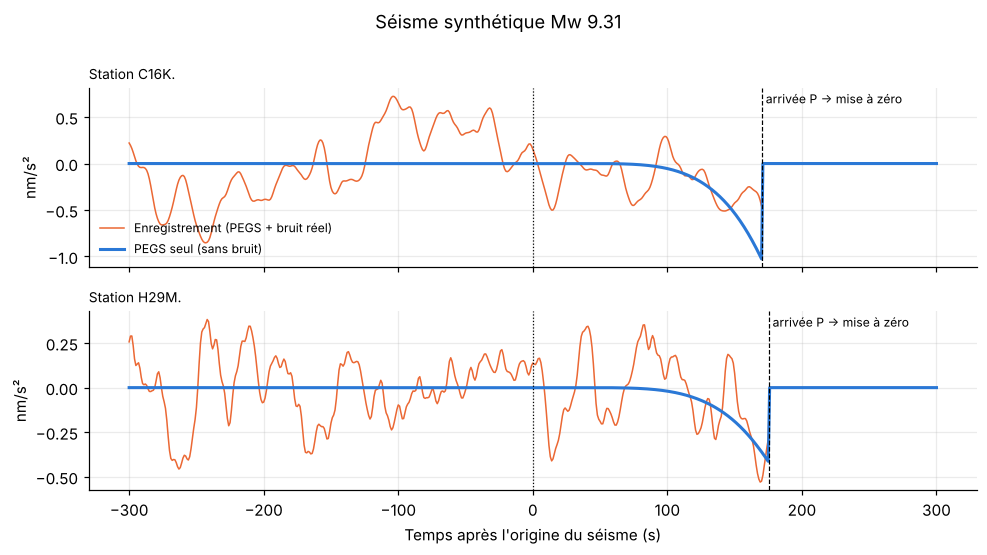

In [6]:
gtr = io.load_graph_split(C.GRAPH_DB_FILE, "train")
t = np.arange(gtr["data"].shape[2]) - C.GRAPH_ORIGIN_IDX     # temps relatif à l'origine (s)
e = int(np.argmax(gtr["mw"]))                                 # le plus gros séisme du train
amp = np.abs(gtr["pegs"][e]).max(1)
stations = [int(np.argmax(amp)), int(np.argsort(amp)[len(amp) // 2])]   # station la plus forte, station médiane

fig, axes = plt.subplots(len(stations), 1, figsize=(9, 5), sharex=True)
for ax, s in zip(axes, stations):
    ax.plot(t, gtr["data"][e, s] * 1e9, color=C.C_NOISY, lw=1, label="Enregistrement (PEGS + bruit réel)")
    ax.plot(t, gtr["pegs"][e, s] * 1e9, color=C.C_SIGNAL, lw=2, label="PEGS seul (sans bruit)")
    ax.axvline(0, color="k", lw=0.8, ls=":"); ax.axvline(gtr["tp"][e, s], color="k", lw=0.8, ls="--")
    ax.text(gtr["tp"][e, s] + 3, ax.get_ylim()[1] * 0.8, "arrivée P → mise à zéro", fontsize=8)
    ax.set_ylabel("nm/s²"); ax.set_title(f"Station {sta.station[s]}", fontsize=9, loc="left")
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
axes[-1].set_xlabel("Temps après l'origine du séisme (s)")
fig.suptitle(f"Séisme synthétique Mw {gtr['mw'][e]:.2f}", y=1.0)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_exemple_signal.png"); plt.show()

**Lecture** : avant l'origine (t < 0) il n'y a que du bruit ; après, le PEGS (bleu) se superpose au bruit (orange)
jusqu'à l'arrivée de l'onde P, où le signal est **volontairement mis à zéro** pour n'utiliser que l'information
arrivée à la vitesse de la lumière. Même pour un très gros séisme, le PEGS n'est visible à l'œil que sur les stations
les mieux placées : sur une station « moyenne », il est noyé dans le bruit.

## 5. Qualité : valeurs manquantes, stations muettes, zéros

In [7]:
qual = []
for name, d in [("graph_db train", gtr)] + [(r, io.load_graph_split(C.REAL_DIR / r, "test")) for r in real.fichier]:
    x = d["data"]
    qual.append({"jeu": name, "NaN": int(np.isnan(x).sum()), "inf": int(np.isinf(x).sum()),
                 "stations sans données (%)": round(100 * (~d["flag"]).mean(), 1),
                 "traces entièrement nulles (%)": round(100 * (np.abs(x).max(2) == 0).mean(), 1)})
noise = io.load_noise(C.NOISE_FILE)
qual.append({"jeu": "bruit (24 fenêtres)", "NaN": int(np.isnan(noise["noise"]).sum()), "inf": 0,
             "stations sans données (%)": round(100 * (~noise["flag"]).mean(), 1),
             "traces entièrement nulles (%)": round(100 * (np.abs(noise["noise"]).max(2) == 0).mean(), 1)})
pd.DataFrame(qual)

,jeu,NaN,inf,stations sans données (%),traces entièrement nulles (%)
0,graph_db train,0,0,4.6,4.6
1,201801230931A_complete.h5,0,0,12.5,12.5
2,202007220612A_complete.h5,0,0,10.6,10.6
3,202010192054A_complete.h5,0,0,8.8,8.8
4,202107290615A_legacy.h5,0,0,5.1,5.1
5,bruit (24 fenêtres),0,0,4.6,4.6


**Constat** : **aucun NaN**. Les données manquantes sont codées autrement : une station sans données a une trace
**entièrement à zéro** et `flag = False` (≈ 5 % en synthétique, 5 à 13 % sur les séismes réels).

**Décision** : on n'impute pas (inventer un signal serait faux physiquement). On utilisera `flag` pour **ignorer**
ces stations dans le calcul des caractéristiques, et le **nombre de stations actives** sera lui-même une variable.
Attention aussi : les zéros après `tp` ne sont **pas** des données manquantes mais un choix de conception.

## 6. Le bruit réel : niveau et contenu fréquentiel

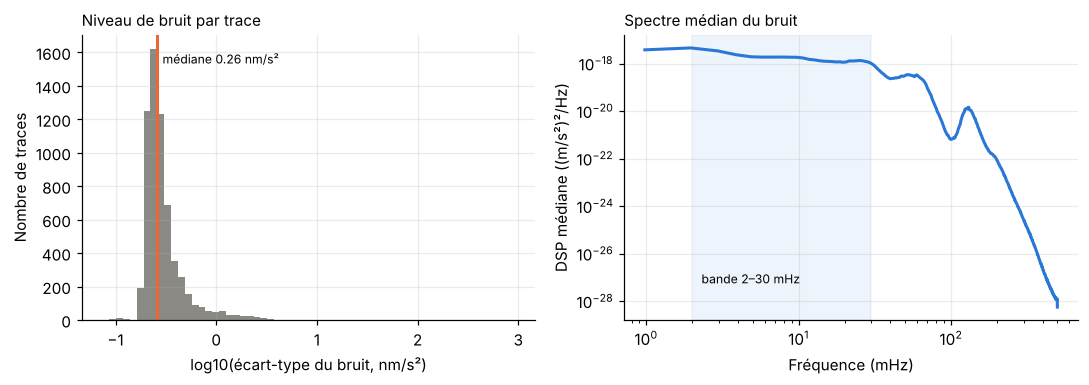

Quantiles du niveau de bruit (nm/s²) : 5% 0.19 | 50% 0.26 | 95% 0.77 | max 923


In [8]:
ok = noise["flag"]
lvl = noise["noiselevel"][ok] * 1e9
f, p = welch(noise["noise"][ok][:1000], fs=C.FS, nperseg=1024)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.hist(np.log10(lvl), bins=60, color=C.C_MUTED)
a1.axvline(np.log10(np.median(lvl)), color=C.C_NOISY, lw=2)
a1.text(np.log10(np.median(lvl)) + 0.05, a1.get_ylim()[1] * 0.9, f"médiane {np.median(lvl):.2f} nm/s²", fontsize=8)
a1.set_xlabel("log10(écart-type du bruit, nm/s²)"); a1.set_ylabel("Nombre de traces")
a1.set_title("Niveau de bruit par trace", loc="left", fontsize=10)
a2.loglog(f[1:] * 1e3, np.median(p, 0)[1:], color=C.C_SIGNAL, lw=2)
a2.axvspan(2, 30, color=C.C_SIGNAL, alpha=0.08); a2.text(2.3, np.median(p, 0)[1:].min() * 10, "bande 2–30 mHz", fontsize=8)
a2.set_xlabel("Fréquence (mHz)"); a2.set_ylabel("DSP médiane ((m/s²)²/Hz)")
a2.set_title("Spectre médian du bruit", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_bruit.png"); plt.show()
print(f"Quantiles du niveau de bruit (nm/s²) : 5% {np.quantile(lvl,.05):.2f} | 50% {np.median(lvl):.2f} | "
      f"95% {np.quantile(lvl,.95):.2f} | max {lvl.max():.0f}")

**Lecture** : le bruit typique est de **~0,26 nm/s²**, du même ordre que les PEGS (≤ 1 nm/s²) : le rapport
signal/bruit est faible, c'est toute la difficulté. Quelques traces ont un bruit énorme (jusqu'à ~900 nm/s²,
probablement d'autres séismes) → il faudra des caractéristiques **robustes** (médianes, quantiles) et un
**écrêtage**. Le spectre chute au-delà de 30–50 mHz : le bruit est **déjà filtré** dans la bande des PEGS.

## 7. La cible : distribution des magnitudes

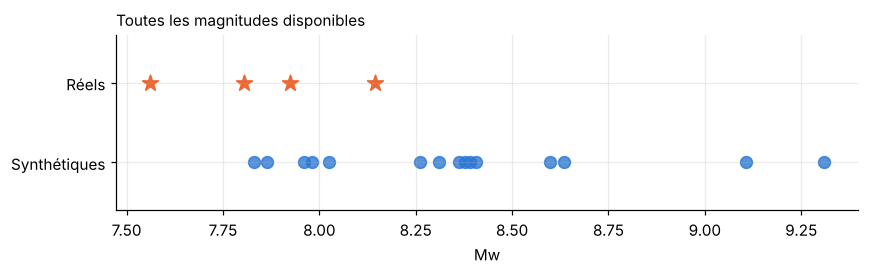

count    15.00
mean      8.36
std       0.43
min       7.83
25%       8.00
50%       8.36
75%       8.50
max       9.31
Name: mw, dtype: float64

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.scatter(meta.mw, np.zeros(len(meta)), s=60, color=C.C_SIGNAL, alpha=0.8, label=f"Synthétiques fournis ({len(meta)})")
ax.scatter(real.mw, np.ones(len(real)), s=120, marker="*", color=C.C_NOISY, label=f"Réels ({len(real)})")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Synthétiques", "Réels"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Mw"); ax.set_title("Toutes les magnitudes disponibles", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_magnitudes.png"); plt.show()
meta.mw.describe().round(2)

**Lecture** : seulement **15 séismes synthétiques** (Mw 7,8 à 9,3) et **4 réels** (Mw 7,6 à 8,1).
C'est **très en dessous** du minimum de ~1 000 lignes nécessaire, et beaucoup trop peu pour XGBoost.

**Conséquence** : il faut **générer** une base plus grande avec les briques fournies (noyaux + bruit réel),
exactement comme le font les auteurs (512 000 séismes dans l'article). C'est l'objet du notebook 02.

## 8. Relation signal ↔ magnitude : l'amplitude ne suffit pas

On compare, pour chaque séisme, l'amplitude maximale du PEGS sur le réseau, et le nombre de stations où le
PEGS dépasse le niveau de bruit typique de la station.

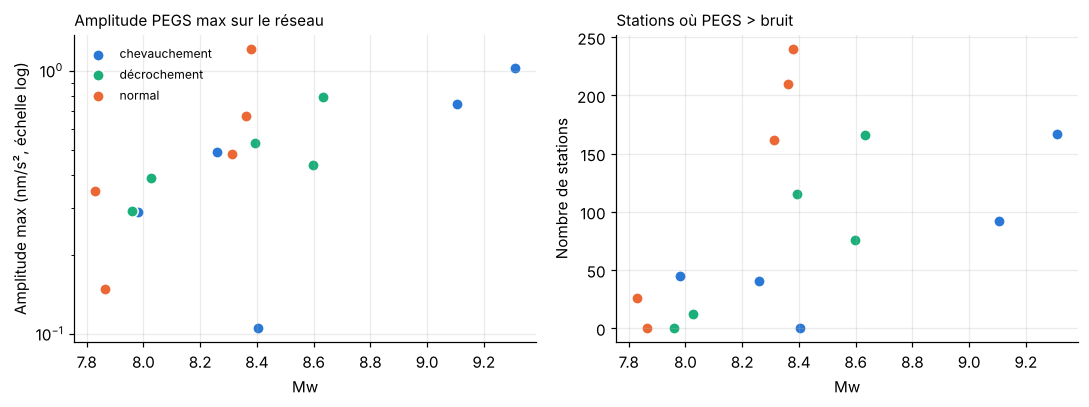

Corrélation log10(amplitude max) vs Mw : 0.58


,mw,mecanisme,amp_max_nm,n_stations_SNR>1
4,7.83,normal,0.35,26
1,7.86,normal,0.15,0
7,7.96,décrochement,0.29,0
5,7.98,chevauchement,0.29,45
12,8.03,décrochement,0.39,12
0,8.26,chevauchement,0.49,41
2,8.31,normal,0.48,162
9,8.36,normal,0.67,210
8,8.38,normal,1.21,240
3,8.39,décrochement,0.53,115


In [10]:
st_noise = np.nanmedian(np.where(noise["flag"], noise["noiselevel"], np.nan), axis=0)   # bruit médian par station
amp_sta = np.abs(pegs).max(2)                                                            # (séisme, station)
meta["amp_max_nm"] = amp_sta.max(1) * 1e9
with np.errstate(invalid="ignore", divide="ignore"):
    meta["n_stations_SNR>1"] = (amp_sta / st_noise > 1).sum(1)
meta["mecanisme"] = pd.cut(meta.rake % 360, [0, 45, 135, 225, 315, 360],
                           labels=["décrochement", "chevauchement", "décrochement ", "normal", "décrochement  "],
                           ordered=False).astype(str).str.strip()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
colors = {"chevauchement": C.C_SIGNAL, "normal": C.C_NOISY, "décrochement": "#1baf7a"}
for m, g in meta.groupby("mecanisme"):
    a1.scatter(g.mw, g.amp_max_nm, s=55, color=colors[m], label=m, edgecolor="white")
    a2.scatter(g.mw, g["n_stations_SNR>1"], s=55, color=colors[m], label=m, edgecolor="white")
a1.set_yscale("log"); a1.set_xlabel("Mw"); a1.set_ylabel("Amplitude max (nm/s², échelle log)")
a1.set_title("Amplitude PEGS max sur le réseau", loc="left", fontsize=10)
a2.set_xlabel("Mw"); a2.set_ylabel("Nombre de stations"); a2.set_title("Stations où PEGS > bruit", loc="left", fontsize=10)
a1.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_amplitude_vs_mw.png"); plt.show()
print("Corrélation log10(amplitude max) vs Mw :", round(np.corrcoef(np.log10(meta.amp_max_nm), meta.mw)[0, 1], 2))
meta[["mw", "mecanisme", "amp_max_nm", "n_stations_SNR>1"]].sort_values("mw").round(2)

**Lecture** : l'amplitude augmente avec Mw, mais la relation est **bruitée** (corrélation ≈ 0,58 sur 15 points) :
à magnitude égale, le **mécanisme** et la **position** de la source changent beaucoup l'amplitude
(exemple : un séisme Mw 8,4 à 0,11 nm/s² contre un Mw 8,4 à 1,2 nm/s²). Sous Mw ≈ 8, presque aucune station
ne voit le PEGS au-dessus du bruit → on s'attend à ce que **tous les modèles** peinent dans cette zone.
Les caractéristiques devront donc décrire **la répartition spatiale** du signal sur le réseau, pas seulement son maximum.

## 9. Subtilité de la cible : magnitude finale ou magnitude « déjà atteinte » ?

Un grand séisme dure longtemps (la rupture d'un Mw 9 dure plusieurs minutes). Le PEGS enregistré à un instant *T*
ne reflète que le moment sismique **déjà libéré** à *T*. On calcule Mw(T) à partir de la fonction source fournie :
$M_w(T) = \frac{2}{3}\left(\log_{10} \int_0^T \dot M_0(t)\,dt - 9{,}1\right)$.

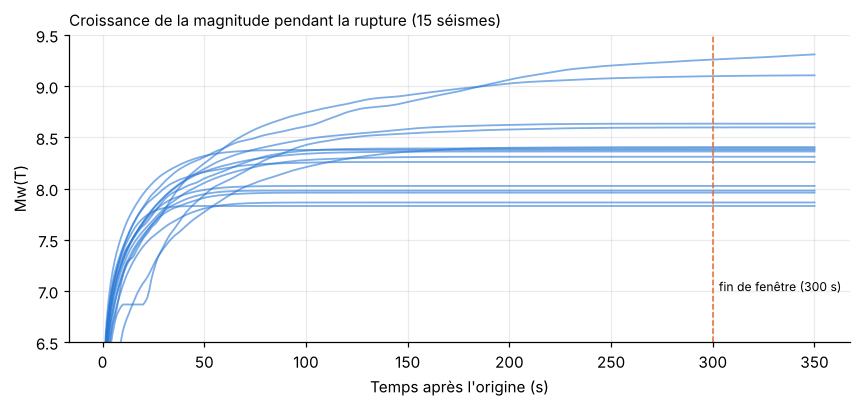

,Mw finale,Mw à 60 s,Mw à 120 s,Mw à 300 s
4,7.83,7.83,7.83,7.83
1,7.86,7.84,7.86,7.86
7,7.96,7.94,7.96,7.96
5,7.98,7.97,7.98,7.98
12,8.03,8.01,8.03,8.03
0,8.26,8.20,8.26,8.26
2,8.31,8.13,8.30,8.31
9,8.36,8.23,8.35,8.36
8,8.38,8.35,8.38,8.38
3,8.39,8.17,8.39,8.39


In [11]:
def mw_at(momrate_row, T):
    m0 = momrate_row[: int(T) + 1].sum() * (1 / C.FS)   # intégrale du taux de moment jusqu'à T (N·m)
    return (np.log10(m0) - 9.1) / 1.5 if m0 > 0 else np.nan

fig, ax = plt.subplots(figsize=(8, 3.8))
Ts = np.arange(1, momrate.shape[1])
for i in np.argsort(meta.mw.values):
    ax.plot(Ts, [mw_at(momrate[i], T) for T in Ts], color=C.C_SIGNAL, alpha=0.6, lw=1.2)
ax.axvline(300, color=C.C_NOISY, ls="--", lw=1); ax.text(303, 7.0, "fin de fenêtre (300 s)", fontsize=8)
ax.set_ylim(6.5, 9.5); ax.set_xlabel("Temps après l'origine (s)"); ax.set_ylabel("Mw(T)")
ax.set_title("Croissance de la magnitude pendant la rupture (15 séismes)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "01_mw_t.png"); plt.show()
cmp = pd.DataFrame({"Mw finale": meta.mw, "Mw à 60 s": [mw_at(m, 60) for m in momrate],
                    "Mw à 120 s": [mw_at(m, 120) for m in momrate], "Mw à 300 s": [mw_at(m, 300) for m in momrate]})
cmp.sort_values("Mw finale").round(2)

**Lecture** : les séismes jusqu'à Mw ~8,6 ont atteint leur magnitude finale (à ~0,1 près) en 2 minutes ; un Mw 9,3
n'en est qu'à Mw ≈ 8,4 à 1 minute et ≈ 8,7 à 2 minutes. **Décision à prendre** : la cible sera la Mw **finale**, et on
fixera un **instant de décision** (par ex. 300 s, la fin de la fenêtre fournie). Prédire une Mw finale très grande
trop tôt est physiquement impossible : c'est une cause **attendue** de sous-estimation des grandes magnitudes
(analysée au notebook 04).

## 10. Audit de fuite de données

Question : *qu'est-ce qui est réellement connu au moment de la décision (quelques minutes après le début du séisme) ?*

| Variable | Connue au moment de la décision ? | Décision |
|---|---|---|
| `data` (signal bruité) jusqu'à l'onde P | ✅ c'est ce que mesurent les sismomètres | **Entrée du modèle** |
| `flag` (station active) | ✅ | Utilisée pour ignorer les stations muettes |
| `tp` (arrivée P par station) | ✅ en pratique (détecteur d'onde P) | Utilisée **seulement** pour délimiter la fenêtre utile |
| `pegs` (signal SANS bruit) | ❌ n'existe pas dans la réalité | **Exclue** — l'utiliser serait tricher |
| `mw`, `m0` | ❌ c'est la cible | Cible uniquement |
| `momrate` / `stf` (fonction source) | ❌ dérivée de la cible | **Exclue** |
| `mt`, `strike`, `dip`, `rake` (mécanisme) | ❌ inconnus en temps réel | **Exclus** (gardés pour l'analyse des erreurs) |
| `srclat`, `srclon`, `srcdep` | ⚠️ estimables via les ondes P, mais pas fournies en temps réel ici | **Exclues** par prudence (gardées pour l'analyse des erreurs et le regroupement) |
| `noiselevel` | ✅ mesurable avant le séisme (bruit pré-événement) | Recalculée nous-mêmes sur la partie t < 0 |

**Autre risque de fuite** : le **même extrait de bruit réel** réutilisé dans le train et le test. Lors de la
génération, on attribuera chaque fenêtre de bruit à **un seul** des deux ensembles, comme les auteurs.

## 11. Bilan de l'analyse

1. **Structure** : 273 stations (Alaska), composante verticale, 1 Hz, m/s², fenêtres de 601 s centrées sur l'origine,
   signal mis à zéro après l'onde P.
2. **Qualité** : aucun NaN ; ~5 % de stations sans données (traces à zéro, `flag=False`) ; bruit très hétérogène
   avec quelques traces aberrantes.
3. **Cible** : 15 séismes synthétiques seulement → **base à générer** avant toute modélisation.
4. **Physique** : PEGS ≈ niveau du bruit ; amplitude dépendante du mécanisme et de la position ; seuil de
   détectabilité vers Mw ~8.
5. **Données réelles** : 4 séismes réels, utilisés uniquement comme **test final hors distribution**.